### Evaluación Árboles de decisión y Random Forest destinado a `mes_lluvioso`

**Configuración de atributos y objetivo a evaluar**

In [1]:
X_config = ["hum_carrasco","hum_salto","tmax_carrasco","tmin_carrasco","tmax_salto","tmin_salto",
     "dir_viento_carrasco_prom","int_viento_carrasco_prom",
     "int_racha_viento_carrasco_prom","dir_viento_salto_prom","int_viento_salto_prom",
     "int_racha_viento_salto_prom","vis_carrasco_prom","vis_salto_prom","fen_carrasco_17"]

y_config = ["mes_lluvioso"]

import warnings # Simplemente para que no ensucie la salida cuando la precisión es 0
from sklearn.exceptions import UndefinedMetricWarning

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)


### Caso Árbol de decisión implementación propia
- Emplea datos discretizados
1. **Carga de librerías y módulo propio**  
   Se importa el módulo `algoritmos_clasificacion`

2. **Carga del dataset**  
   ```python
   S = t.cargarDataset("data_mes")
3. **Validación del modelo con CV con 5 splits**<br>
   Arroja un dataframe con los scorings promedios y desviaciones de cada conjunto

In [2]:
import algoritmos_clasificacion as t
import importlib
importlib.reload(t)

# Carga dataset
S = t.cargarDataset("data_mes")

# Configuración atributos y objetivo válidos
X = S[X_config]

y = S[y_config].squeeze() #pasa de df a serie

# #configuración de hiperparámetros a evaluar
criterios = ["gain", "gini", "gain_ratio"]
min_info_gains = [0.003, 0.004, 0.006, 0.008]

# Train/Test split (80/20 estratificado)
X_train, X_test, y_train, y_test, = t.split_data(X,y)

# Validación cruzada para selección de hiperparámetros
df_validacion_id3, best_cfg_F, best_cfg_A, best_cfg_P, best_cfg_R = t.validarModelo(X_train, y_train, n_splits=5, criterios=criterios, hiperparams=min_info_gains)

print("\n Resultados CV")
print(df_validacion_id3.round(4).to_string(index=False))
#tiempo est: 7min




 Resultados CV
  criterio  min_info_gain  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
      gain          0.003         0.8028        0.0031   0.7099  0.0039       0.6592      0.0075          0.7691         0.0089
      gain          0.004         0.8028        0.0029   0.7098  0.0039       0.6594      0.0074          0.7689         0.0084
      gain          0.006         0.8017        0.0022   0.7069  0.0043       0.6536      0.0112          0.7698         0.0086
      gain          0.008         0.6341        0.0001   0.0000  0.0000       0.0000      0.0000          0.0000         0.0000
      gini          0.003         0.8009        0.0036   0.7073  0.0042       0.6575      0.0069          0.7655         0.0099
      gini          0.004         0.7946        0.0113   0.6921  0.0245       0.6326      0.0371          0.7654         0.0107
      gini          0.006         0.6341        0.0001   0.0000  0.0000       0.0000    

**Gráfica de errores según hiperparámetros obtenidos en CV**

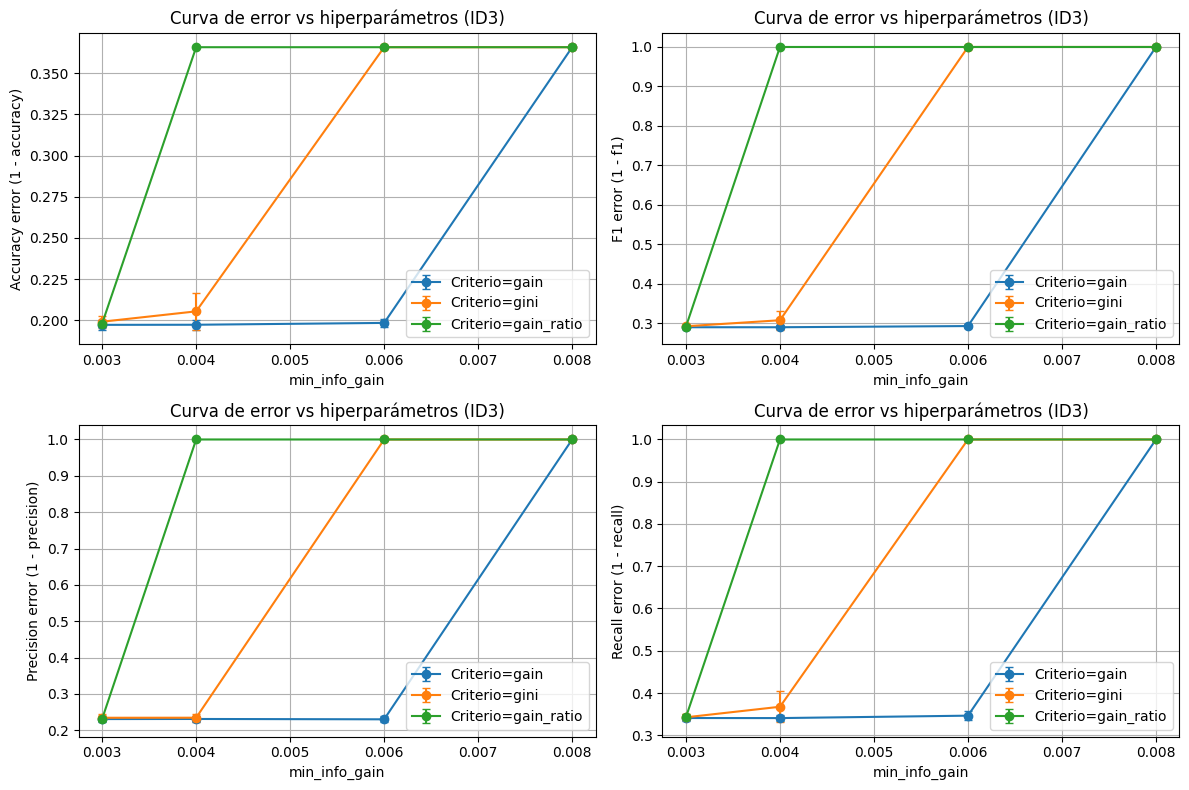

In [ ]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

t.funcGraficaError(df_validacion_id3, metric="accuracy", modelo="ID3", ax=axs[0,0])
t.funcGraficaError(df_validacion_id3, metric="f1", modelo="ID3", ax=axs[0,1])
t.funcGraficaError(df_validacion_id3, metric="precision", modelo="ID3", ax=axs[1,0])
t.funcGraficaError(df_validacion_id3, metric="recall", modelo="ID3", ax=axs[1,1])

plt.tight_layout()
plt.show()

#tiempo est: 1seg

1. **Testeo con mejores configuraciones de hiperparámetros obtenidos**  
2. **Obtención de Matrices de Confusión**


EVALUACIÓN FINAL EN TEST según mejor criterio por f-score:
mejor criterio:  gain mejor min_info_gain:  0.003
Accuracy : 0.8165228113440197
F1       : 0.7296511627906976
Recall   : 0.677006068779501
Precision: 0.7911741528762806

EVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:
mejor criterio:  gain mejor min_info_gain:  0.003
Accuracy : 0.8165228113440197
F1       : 0.7296511627906976
Recall   : 0.677006068779501
Precision: 0.7911741528762806


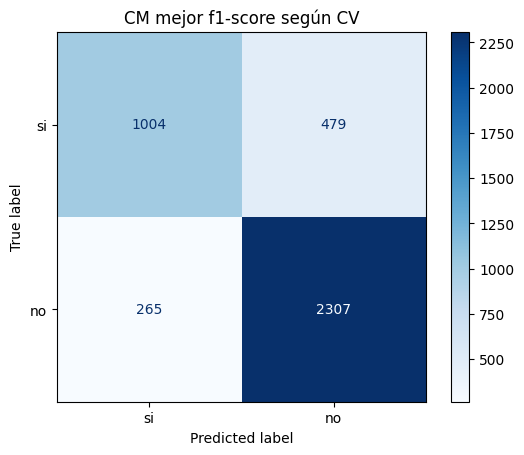

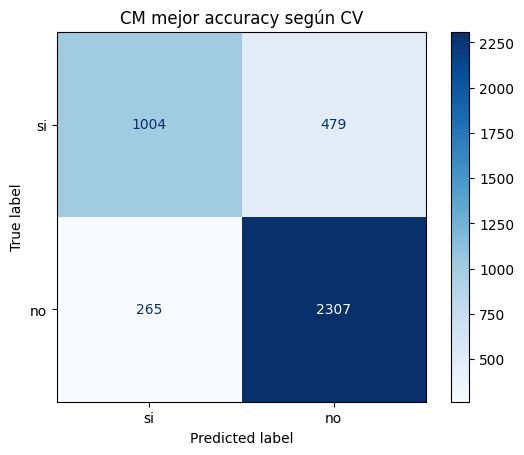

In [ ]:
# Evaluación final en test según mejores configuraciones ID3 modificado
y_pred_f = t.testearModelo("ID3", best_cfg_F, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por f-score:")
t.imprimirMetricas("ID3", best_cfg_F, y_test, y_pred_f)

y_pred_a = t.testearModelo("ID3", best_cfg_A, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:")
t.imprimirMetricas("ID3", best_cfg_A, y_test, y_pred_a)

# Matrices de confusión
t.graficar_matriz_confusion(y_test, y_pred_f, labels=['si', 'no'], title="CM mejor f1-score según CV")

t.graficar_matriz_confusion(y_test, y_pred_a, labels=['si', 'no'], title="CM mejor accuracy según CV")


#timepo est: 1min

In [ ]:
#PRINT ARBOL ID3, descomentar si se prefiere, resulta un arbol muy amplio

# arbol = t.generacion_ID3(S, list(X.columns), "mes_lluvioso", best_cfg_F["min_info_gain"], best_cfg_F["criterio"])
# dot = t.graficar_arbol(arbol)
# dot.render("ARBOL mejor parametrización según f-score", format="png", view=True)

## Caso Random Forest de Sickit Learn
- Emplea datos continuos
1. **Carga de librerías y módulo propio**  
   Se importa el módulo `algoritmos_clasificacion`

2. **Carga del dataset**  
   ```python
   S = t.cargarDataset("data_mes_c")
3. **Validación del modelo con CV con 5 splits**<br>
   Arroja un dataframe con los scorings promedios y desviaciones de cada conjunto

In [ ]:
# -------------------------------------------- RANDOM FOREST -------------------------------------------------
import algoritmos_clasificacion as t
import importlib
importlib.reload(t)

# Cargar dataset
S2 = t.cargarDataset("data_mes_c")

# Definir los atributos y objetivo validos
X = S2[X_config]

y = S2[y_config].squeeze() #pasa de df a serie

#configuración de hiperparámetros a evaluar
n_estimators_values = [100, 200, 300, 500]

# Train/Test split (80/20 estratificado)
X_train, X_test, y_train, y_test, = t.split_data(X,y)

# Validación cruzada para selección de hiperparámetros
df_validacion_rf, best_cfg_F, best_cfg_A, best_cfg_P, best_cfg_R = t.validarModelo(X_train, y_train, n_splits=5, hiperparams=n_estimators_values)

print("\n Resultados CV")
print(df_validacion_rf.round(4).to_string(index=False))

#tiempo est: 2 min



 Resultados CV
 n_estimators  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
          100         0.9359        0.0019   0.9112  0.0029       0.8990      0.0105          0.9238         0.0086
          200         0.9370        0.0024   0.9129  0.0031       0.9016      0.0089          0.9247         0.0099
          300         0.9376        0.0026   0.9137  0.0036       0.9024      0.0091          0.9253         0.0095
          500         0.9376        0.0028   0.9137  0.0037       0.9033      0.0088          0.9246         0.0092


**Gráfica de errores según hiperparámetros obtenidos en CV**

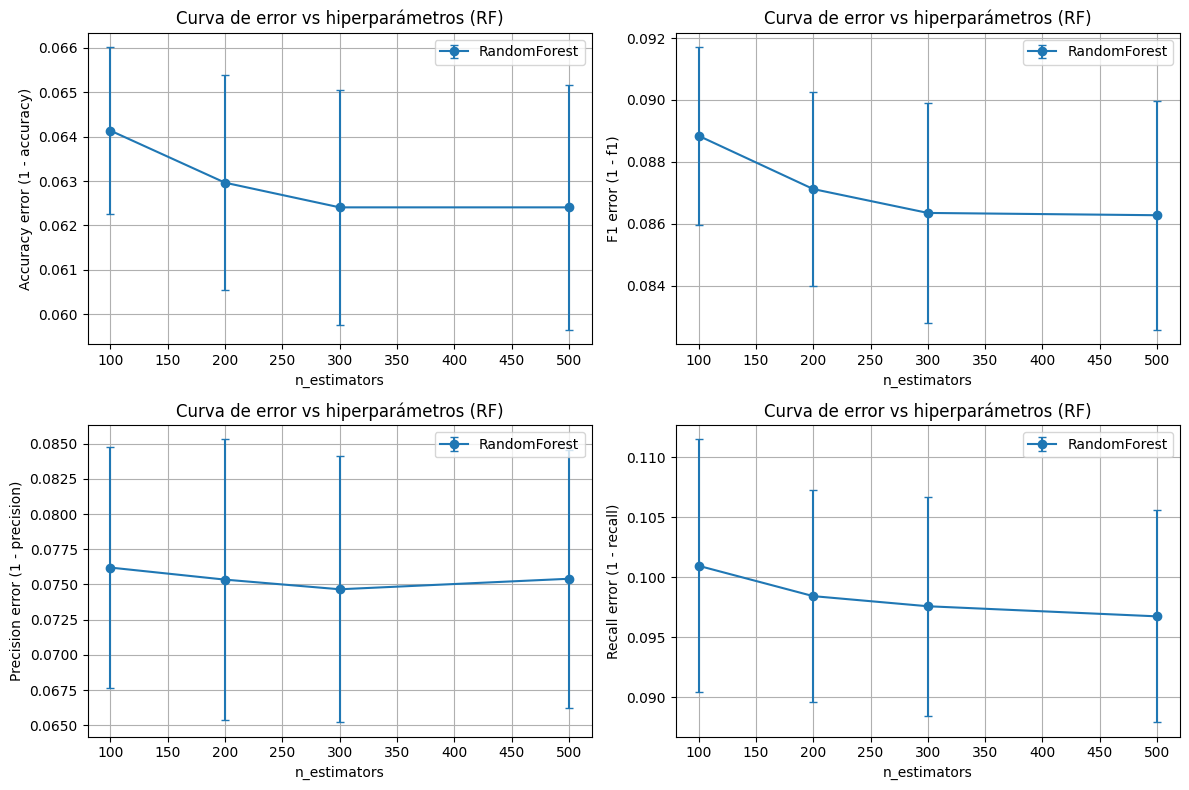

In [ ]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

t.funcGraficaError(df_validacion_rf, metric="accuracy", modelo="RF", ax=axs[0,0])
t.funcGraficaError(df_validacion_rf, metric="f1", modelo="RF", ax=axs[0,1])
t.funcGraficaError(df_validacion_rf, metric="precision", modelo="RF", ax=axs[1,0])
t.funcGraficaError(df_validacion_rf, metric="recall", modelo="RF", ax=axs[1,1])

plt.tight_layout()
plt.show()

#tiempo est: 1seg

1. **Testeo con mejores configuraciones de hiperparámetros obtenidos**  
2. **Obtención de Matrices de Confusión**


EVALUACIÓN FINAL EN TEST según mejor criterio por f-score:
nro arboles:  500
Accuracy : 0.9442663378545006
F1       : 0.9230245231607629
Recall   : 0.9325533379215416
Precision: 0.9136884693189481

EVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:
nro arboles:  300
Accuracy : 0.9457459926017263
F1       : 0.9251191286589516
Recall   : 0.916385704652731
Precision: 0.934020618556701


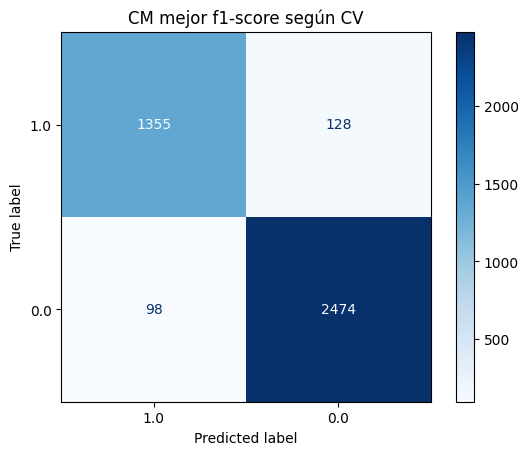

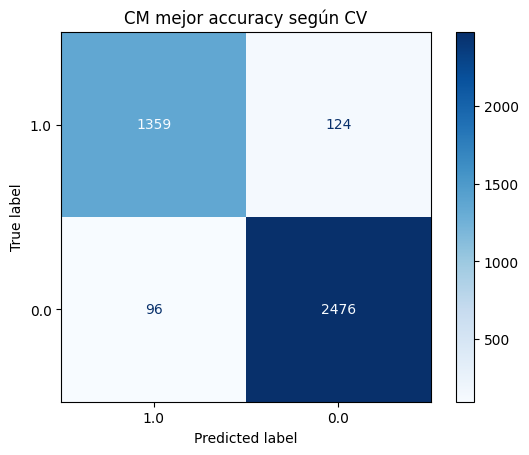

In [ ]:
# Evaluación final en test según mejores configuraciones RANDOM FOREST sickit learn
y_pred_f = t.testearModelo("RF", best_cfg_F, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por f-score:")
t.imprimirMetricas("RF", best_cfg_F, y_pred_f, y_test)

y_pred_a = t.testearModelo("RF", best_cfg_A, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:")
t.imprimirMetricas("RF", best_cfg_A, y_test, y_pred_a)

# Matrices de confusión
t.graficar_matriz_confusion(y_test, y_pred_f, labels=[1.0, 0.0], title="CM mejor f1-score según CV")

t.graficar_matriz_confusion(y_test, y_pred_a, labels=[1.0, 0.0], title="CM mejor accuracy según CV")

#tiempo est: 10seg